# 03. 功能富集

本 notebook 检验 environmental association signals 在位点和基因层级的富集，并实施审稿中要求的条件生物学背景、匹配对照、LD-aware analyses 以及 MAF/LoF sensitivity analyses。


In [2]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

data_dir = os.path.join(os.getcwd(), "data")
source_dir = os.path.join(data_dir, "source")
results_dir = os.path.join(data_dir, "results")
run_dir = os.path.join(os.getcwd(), "run")

enrich_dir = os.path.join(results_dir, "enrichmentv2")
os.makedirs(enrich_dir, exist_ok=True)

载入contexts设定

In [3]:
import json
import gzip

datasets = {
    'genome': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df"), # All variants with MAF >= 0.05
    'cds': pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.cds.maf0.01.h5"), key="df"), # All variants in coding regions with MAF >= 0.01
    'gene': pd.read_hdf(os.path.join(data_dir, "results", "gene_contexts.h5"), key="df") # All genes
}

datasets['genome']['genome'] = True
datasets['cds']['cds'] = True
datasets['gene']['gene'] = True

contexts_settings_json_file = os.path.join(os.getcwd(), "config", "contexts_settings.json")
with open(contexts_settings_json_file, "r") as f:
    contexts_settings = json.load(f)

载入envGWAS结果

In [4]:
import numpy as np

# genome site level envGWAS results
env_id_list = ["bio18", "gsl", "al", "striga"]
env_metadata_df = pd.read_csv(os.path.join(data_dir, "source", "envir_metadata.csv"))
genome_vcf_file = os.path.join(data_dir, "results", "landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz")
cds_vcf_file = os.path.join(data_dir, "results", "landraces_cds_miss0.5_maf0.01_het0.05.vcf.gz")

vcf_files = {
    'genome': genome_vcf_file,
    'cds': cds_vcf_file
}

for env_id in env_id_list:
    env_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.gemma", f"{env_id}.gemma.gwas_df.h5"), key="df")
    env_df = env_df[['ID', 'P_WALD']]
    env_df = env_df.rename(columns={'P_WALD': env_id})
    env_df[env_id] = -np.log10(env_df[env_id])
    datasets['genome'] = datasets['genome'].merge(env_df, on='ID', how='left')
 
    env_cds_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}_cds.gemma", f"{env_id}_cds.gemma.gwas_df.h5"), key="df")
    env_cds_df = env_cds_df[['ID', 'P_WALD']]
    env_cds_df = env_cds_df.rename(columns={'P_WALD': env_id})
    env_cds_df[env_id] = -np.log10(env_cds_df[env_id])
    datasets['cds'] = datasets['cds'].merge(env_cds_df, on='ID', how='left')
    
    env_gene_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.magma", f"{env_id}.magma.gwas_df.h5"), key="df")
    env_gene_df = env_gene_df[['ID', 'P_VALUE']]
    env_gene_df = env_gene_df.rename(columns={'P_VALUE': env_id})
    env_gene_df[env_id] = -np.log10(env_gene_df[env_id])
    datasets['gene'] = datasets['gene'].merge(env_gene_df, on='ID', how='left')

载入contrasts设定

In [5]:
contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

## 1. Genomic compartments

### 1.1 genic_2kb_vs_genome

In [6]:
contrast_id = "genic_2kb_vs_genome"

In [7]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: genic_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: genic_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/genic_2kb_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/genic_2kb_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: genic_2kb_vs_genome


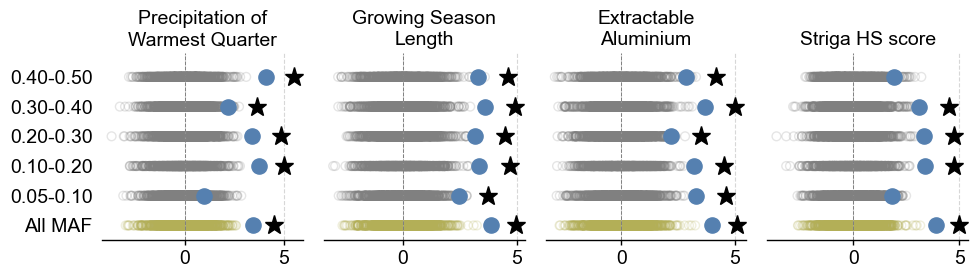

In [8]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 1.2 TE_vs_genome

In [9]:
contrast_id = "TE_vs_genome"

In [10]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: TE_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: TE
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/TE_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/TE_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: TE_vs_genome


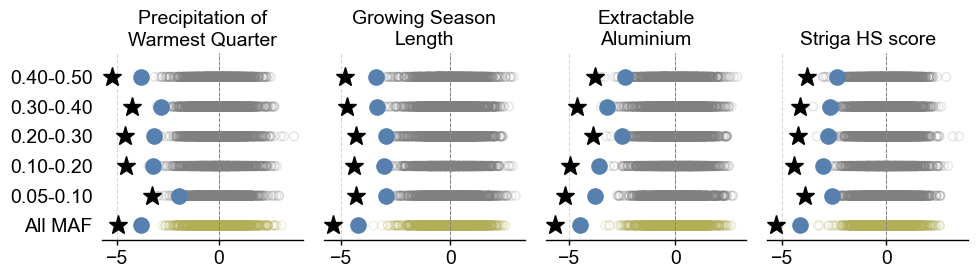

In [11]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 1.3 other_intergenic_vs_genome

In [12]:
contrast_id = "other_intergenic_vs_genome"

In [13]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: other_intergenic_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: other_intergenic
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/other_intergenic_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/other_intergenic_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: other_intergenic_vs_genome


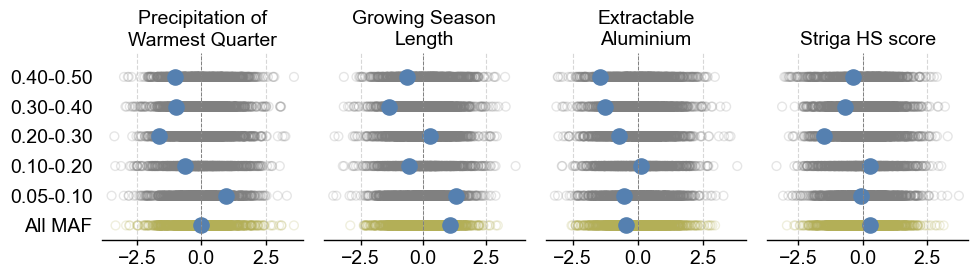

In [14]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 2. Gene Structure

### 2.1 在基因区内部比较

#### 2.1.1 upstream_2kb_vs_genic

In [15]:
contrast_id = "upstream_2kb_vs_genic"

In [16]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: upstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: upstream_2kb & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/upstream_2kb_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/upstream_2kb_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: upstream_2kb_vs_genic


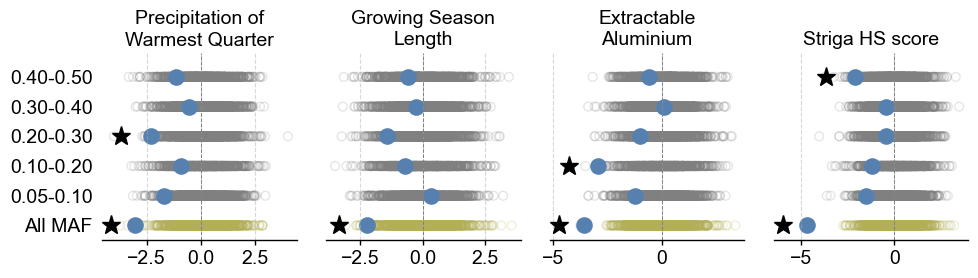

In [17]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.2 five_prime_UTR_vs_genic

In [18]:
contrast_id = "five_prime_UTR_vs_genic"

In [19]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: five_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: five_prime_UTR & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/five_prime_UTR_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/five_prime_UTR_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: five_prime_UTR_vs_genic


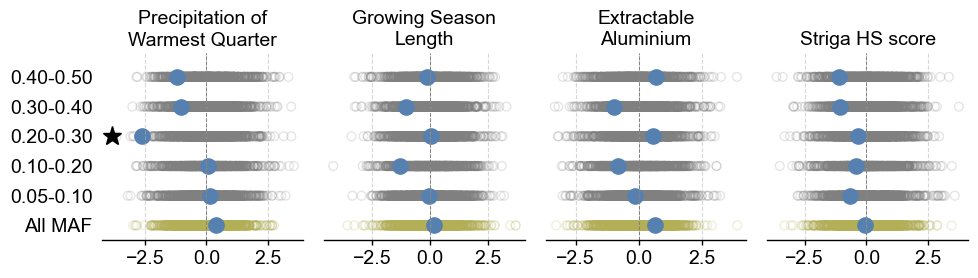

In [20]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.3 CDS_vs_genic

In [21]:
contrast_id = "CDS_vs_genic"

In [22]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: CDS_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: CDS & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/CDS_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/CDS_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: CDS_vs_genic


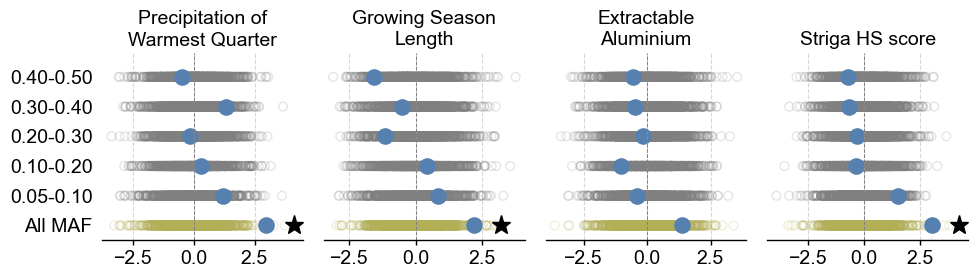

In [23]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.4 intron_vs_genic

In [24]:
contrast_id = "intron_vs_genic"

In [25]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: intron_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: intron & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/intron_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/intron_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: intron_vs_genic


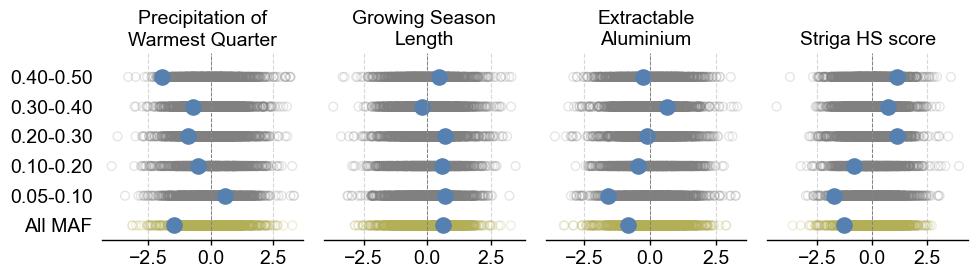

In [26]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.5 three_prime_UTR_vs_genic

In [27]:
contrast_id = "three_prime_UTR_vs_genic"

In [28]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: three_prime_UTR_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: three_prime_UTR & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/three_prime_UTR_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/three_prime_UTR_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: three_prime_UTR_vs_genic


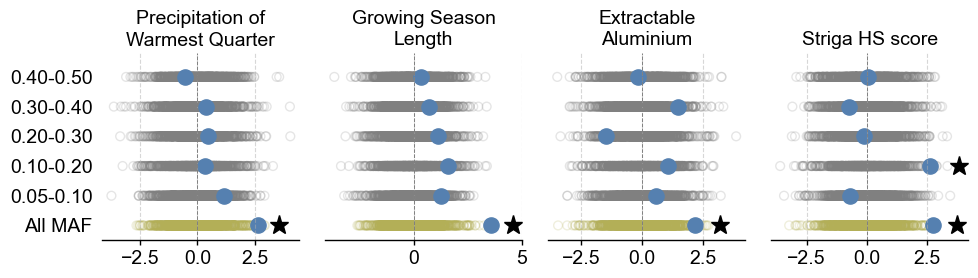

In [29]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.1.6 downstream_2kb_vs_genic

In [30]:
contrast_id = "downstream_2kb_vs_genic"

In [31]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: downstream_2kb_vs_genic
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: downstream_2kb & genic_2kb
  Background set: genic_2kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/downstream_2kb_vs_genic; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/downstream_2kb_vs_genic/feature_coverage.json.gz')

Enrichment results for contrast: downstream_2kb_vs_genic


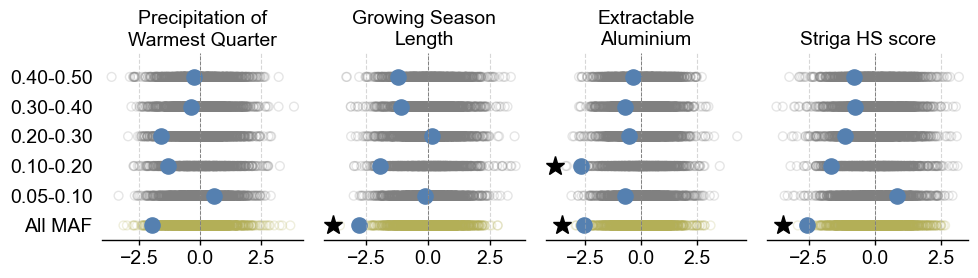

In [32]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 2.2 在基因组范围比较

#### 2.2.1 upstream_2kb_vs_genome

In [33]:
contrast_id = "upstream_2kb_vs_genome"

In [34]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: upstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: upstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/upstream_2kb_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/upstream_2kb_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: upstream_2kb_vs_genome


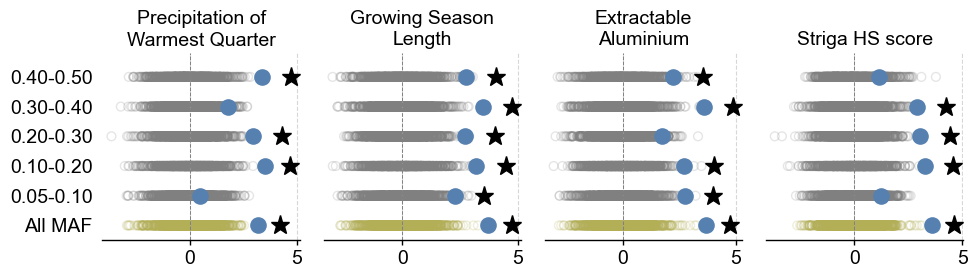

In [35]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.2 five_prime_UTR_vs_genome

In [36]:
contrast_id = "five_prime_UTR_vs_genome"

In [37]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: five_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: five_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/five_prime_UTR_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/five_prime_UTR_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: five_prime_UTR_vs_genome


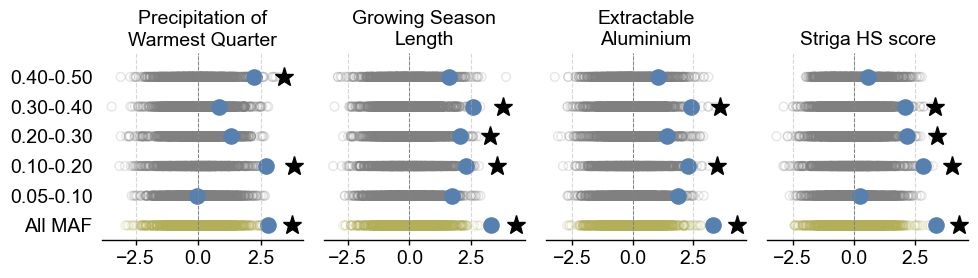

In [38]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.3 CDS_vs_genome

In [39]:
contrast_id = "CDS_vs_genome"

In [40]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: CDS_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: CDS
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/CDS_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/CDS_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: CDS_vs_genome


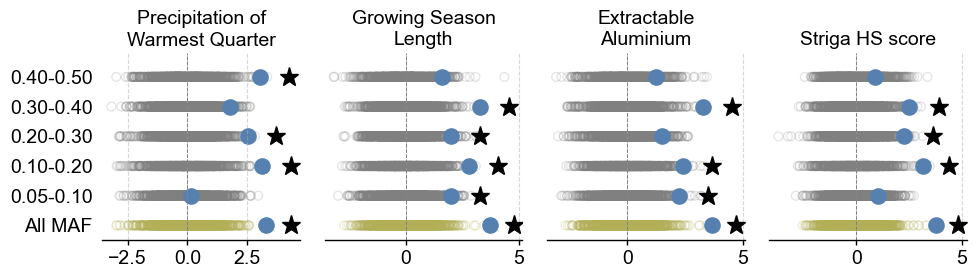

In [41]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.4 intron_vs_genome

In [42]:
contrast_id = "intron_vs_genome"

In [43]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: intron_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: intron
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/intron_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/intron_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: intron_vs_genome


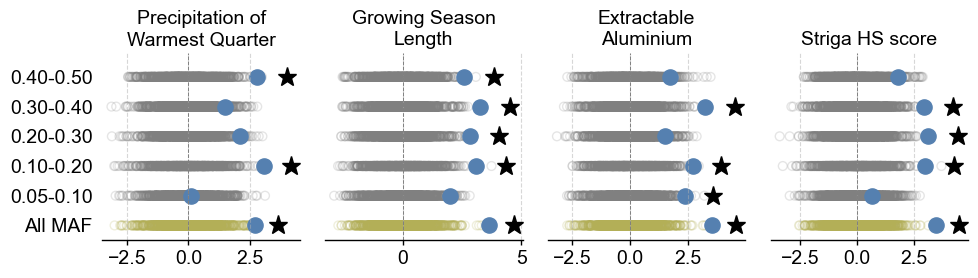

In [44]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.5 three_prime_UTR_vs_genome

In [45]:
contrast_id = "three_prime_UTR_vs_genome"

In [46]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: three_prime_UTR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: three_prime_UTR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/three_prime_UTR_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/three_prime_UTR_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: three_prime_UTR_vs_genome


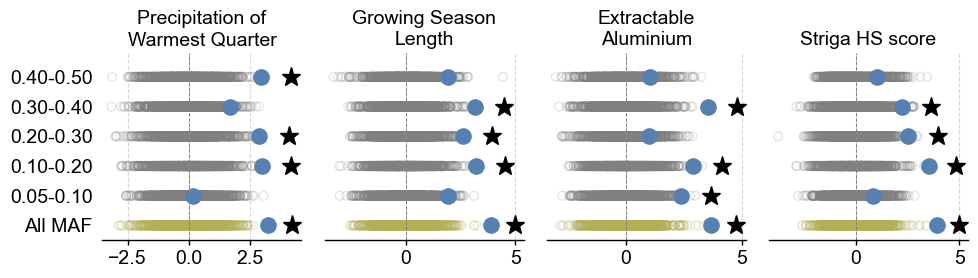

In [47]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.2.6 downstream_2kb_vs_genome

In [48]:
contrast_id = "downstream_2kb_vs_genome"

In [49]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: downstream_2kb_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: downstream_2kb
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/downstream_2kb_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/downstream_2kb_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: downstream_2kb_vs_genome


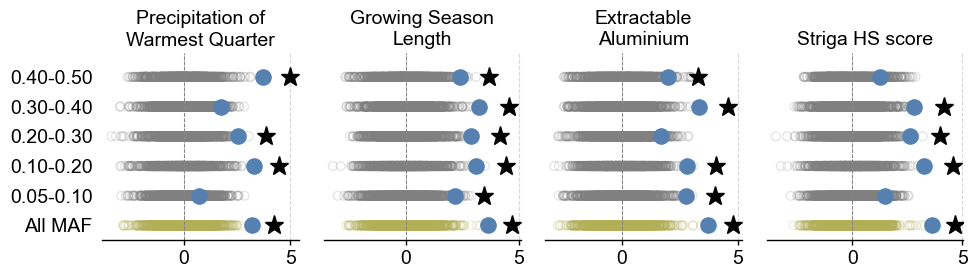

In [50]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 2.3 在CDS中的比较

#### 2.3.1 missense_vs_CDS

In [51]:
contrast_id = "missense_vs_CDS"

In [52]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: missense_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: `missense_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/missense_vs_CDS; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/missense_vs_CDS/feature_coverage.json.gz')

Enrichment results for contrast: missense_vs_CDS


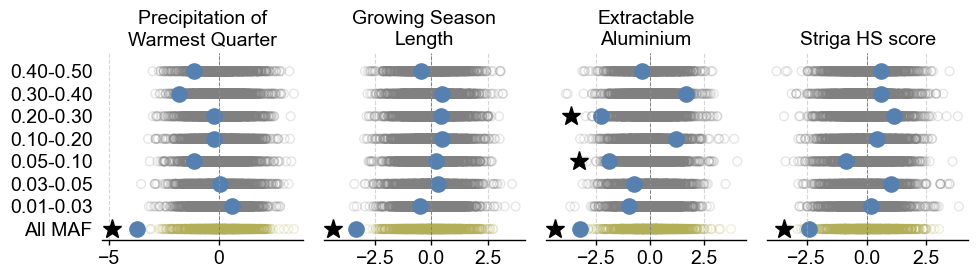

In [53]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.2 synonymous_vs_CDS

In [54]:
contrast_id = "synonymous_vs_CDS"

In [55]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: synonymous_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: `synonymous_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/synonymous_vs_CDS; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/synonymous_vs_CDS/feature_coverage.json.gz')

Enrichment results for contrast: synonymous_vs_CDS


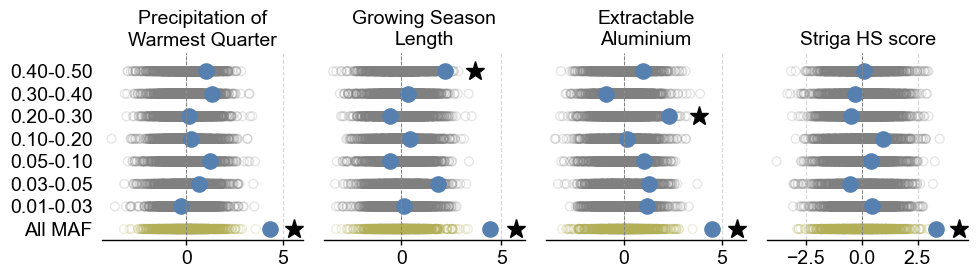

In [56]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.3 putative_LoF_vs_CDS

In [57]:
contrast_id = "putative_LoF_vs_CDS"

In [58]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: putative_LoF_vs_CDS
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: `putative_LoF_cds_0.01`
  Background set: cds
  MAF stratify: ['all', 'maf_0.01_0.03_cds_0.01', 'maf_0.03_0.05_cds_0.01', 'maf_0.05_0.1_cds_0.01', 'maf_0.1_0.2_cds_0.01', 'maf_0.2_0.3_cds_0.01', 'maf_0.3_0.4_cds_0.01', 'maf_0.4_0.5_cds_0.01']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/putative_LoF_vs_CDS; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/putative_LoF_vs_CDS/feature_coverage.json.gz')

Enrichment results for contrast: putative_LoF_vs_CDS


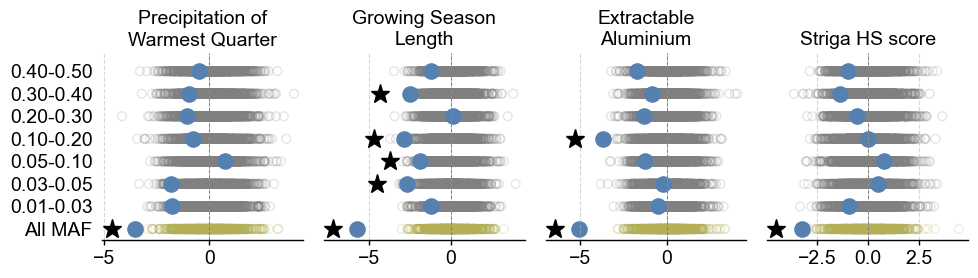

In [59]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01-0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03-0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05-0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10-0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20-0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30-0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40-0.50']
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 2.3.4 putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05

In [60]:
contrast_id = "putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05"

In [61]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=['all'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05
Using dataset: cds
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: `putative_LoF_cds_0.01` & `maf_0.01_0.03_cds_0.01`
  Background set: `putative_LoF_cds_0.01` & `maf_0.03_0.05_cds_0.01`
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05/feature_coverage.json.gz')

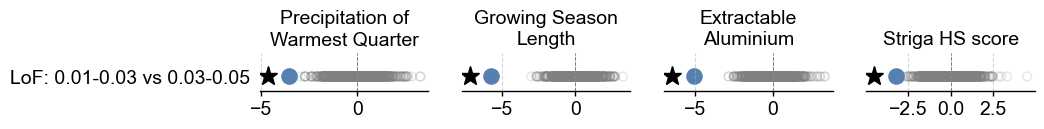

(<Figure size 1000x50 with 4 Axes>,
 array([<Axes: title={'center': 'Precipitation of\nWarmest Quarter'}>,
        <Axes: title={'center': 'Growing Season\nLength'}>,
        <Axes: title={'center': 'Extractable\nAluminium'}>,
        <Axes: title={'center': 'Striga HS score'}>], dtype=object))

In [62]:
from src.enrich import plot_set_enrichment

set_label_map = [
    ['putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05', 'LoF: 0.01-0.03 vs 0.03-0.05'],
]

set_results_json = {}
for contrast_id, results_json_file in [("putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05", results_json_file)]:
    with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
        results_json = json.load(f)
    set_results_json[contrast_id] = results_json

plot_set_enrichment(set_results_json, env_id_list, env_metadata_df, set_label_map, significance_threshold=0.05)

### 2.4 riboSNitches

riboSNitch_vs_gene_body

In [63]:
contrast_id = "riboSNitch_vs_gene_body"

In [64]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: riboSNitch_vs_gene_body
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: riboSNitch & gene_body
  Background set: gene_body
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/riboSNitch_vs_gene_body; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/riboSNitch_vs_gene_body/feature_coverage.json.gz')

Enrichment results for contrast: riboSNitch_vs_gene_body


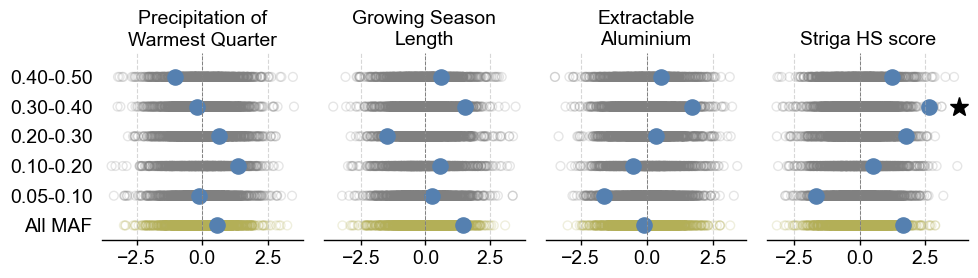

In [65]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 3. Epigenomic features

### 3.1 ACR_vs_genome

In [66]:
contrast_id = "ACR_vs_genome"

In [67]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: ACR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: ACR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/ACR_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/ACR_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: ACR_vs_genome


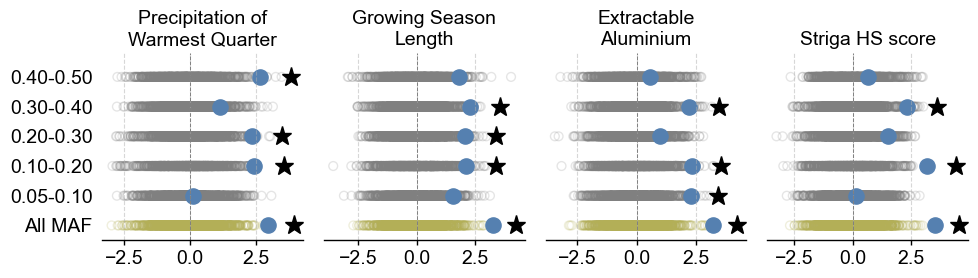

In [68]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 3.2 UMR_vs_genome

In [69]:
contrast_id = "UMR_vs_genome"

In [70]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: UMR_vs_genome
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: UMR
  Background set: genome
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/UMR_vs_genome; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/UMR_vs_genome/feature_coverage.json.gz')

Enrichment results for contrast: UMR_vs_genome


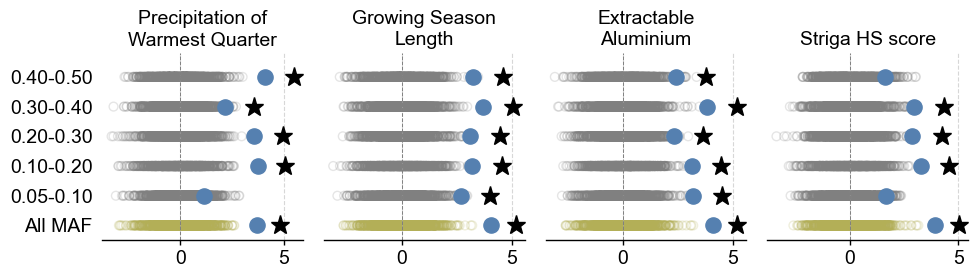

In [71]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 4. Genic proximal and distal

### 4.1 proximal_TE_vs_proximal

In [72]:
contrast_id = "proximal_TE_vs_proximal"

In [73]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: proximal_TE_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: genic_proximal & TE
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_TE_vs_proximal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_TE_vs_proximal/feature_coverage.json.gz')

Enrichment results for contrast: proximal_TE_vs_proximal


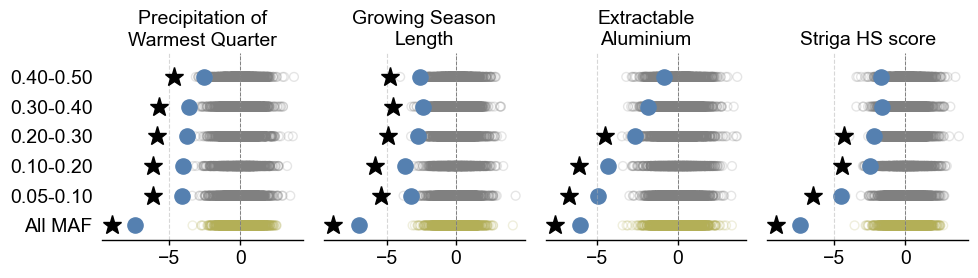

In [74]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.2 distal_TE_vs_distal

In [75]:
contrast_id = "distal_TE_vs_distal"

In [76]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: distal_TE_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: (genome - genic_proximal) & TE
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_TE_vs_distal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_TE_vs_distal/feature_coverage.json.gz')

Enrichment results for contrast: distal_TE_vs_distal


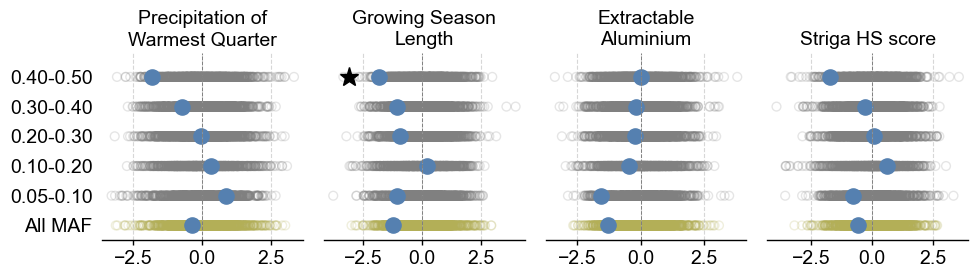

In [77]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.3 proximal_ACR_vs_proximal

In [78]:
contrast_id = "proximal_ACR_vs_proximal"

In [79]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: proximal_ACR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: ACR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_vs_proximal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_vs_proximal/feature_coverage.json.gz')

Enrichment results for contrast: proximal_ACR_vs_proximal


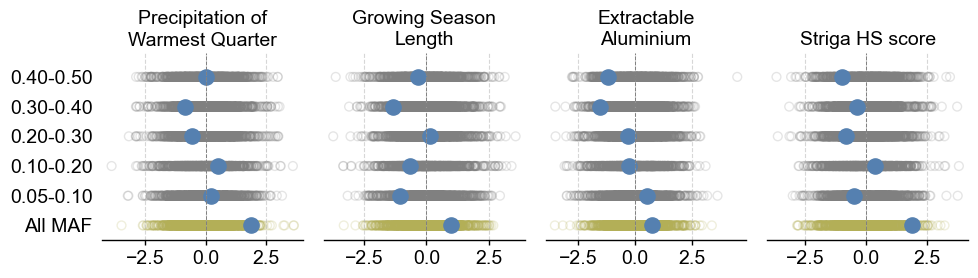

In [80]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.4 distal_ACR_vs_distal

In [81]:
contrast_id = "distal_ACR_vs_distal"

In [82]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: distal_ACR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: (genome - genic_proximal) & ACR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_ACR_vs_distal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_ACR_vs_distal/feature_coverage.json.gz')

Enrichment results for contrast: distal_ACR_vs_distal


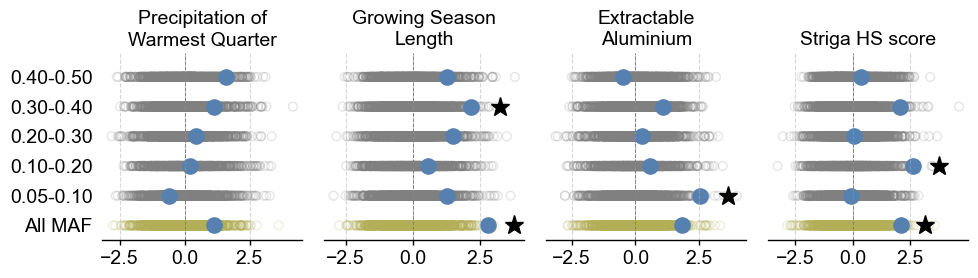

In [83]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.5 proximal_UMR_vs_proximal

In [84]:
contrast_id = "proximal_UMR_vs_proximal"

In [85]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: proximal_UMR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: UMR & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_UMR_vs_proximal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_UMR_vs_proximal/feature_coverage.json.gz')

Enrichment results for contrast: proximal_UMR_vs_proximal


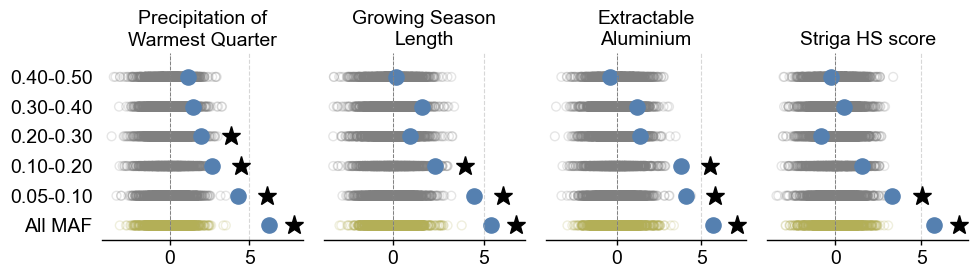

In [86]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.6 distal_UMR_vs_distal

In [87]:
contrast_id = "distal_UMR_vs_distal"

In [88]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: distal_UMR_vs_distal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: (genome - genic_proximal) & UMR
  Background set: genome - genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_UMR_vs_distal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/distal_UMR_vs_distal/feature_coverage.json.gz')

Enrichment results for contrast: distal_UMR_vs_distal


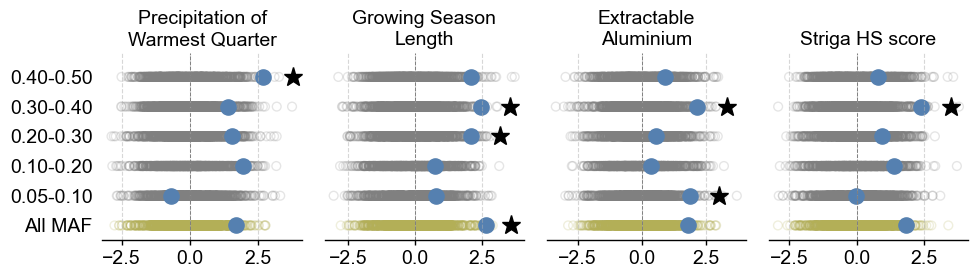

In [89]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.7 proximal_ACR_not_TE_vs_proximal_TE_not_ACR

In [90]:
contrast_id = "proximal_ACR_not_TE_vs_proximal_TE_not_ACR"

In [91]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: (ACR & genic_proximal) - TE
  Background set: (TE & genic_proximal) - ACR
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_not_TE_vs_proximal_TE_not_ACR; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_not_TE_vs_proximal_TE_not_ACR/feature_coverage.json.gz')

Enrichment results for contrast: proximal_ACR_not_TE_vs_proximal_TE_not_ACR


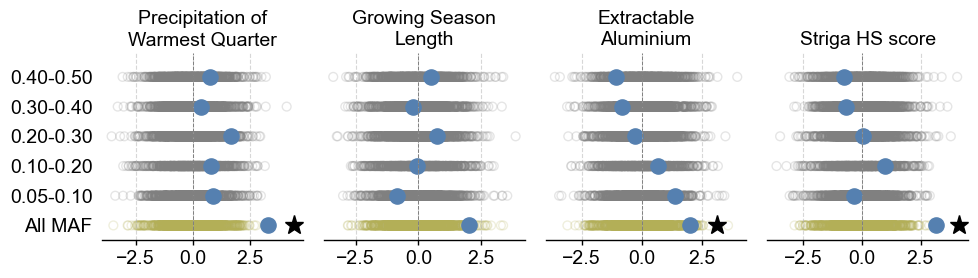

In [92]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 4.8 proximal_ACR_TE_UMR_vs_proximal

In [93]:
contrast_id = "proximal_ACR_TE_UMR_vs_proximal"

In [94]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: proximal_ACR_TE_UMR_vs_proximal
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: (ACR | TE | UMR) & genic_proximal
  Background set: genic_proximal
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_TE_UMR_vs_proximal; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/proximal_ACR_TE_UMR_vs_proximal/feature_coverage.json.gz')

Enrichment results for contrast: proximal_ACR_TE_UMR_vs_proximal


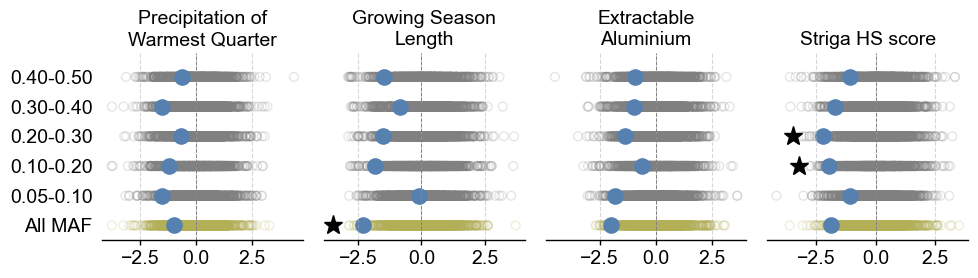

In [95]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

## 5. Evolutionary conservation & Population genetics

### 5.1 Nucleotide diversity (π)

#### 5.1.1 low_pi

In [96]:
contrast_id = "low_pi"

In [97]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: low_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: low_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/low_pi; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/low_pi/feature_coverage.json.gz')

Enrichment results for contrast: low_pi


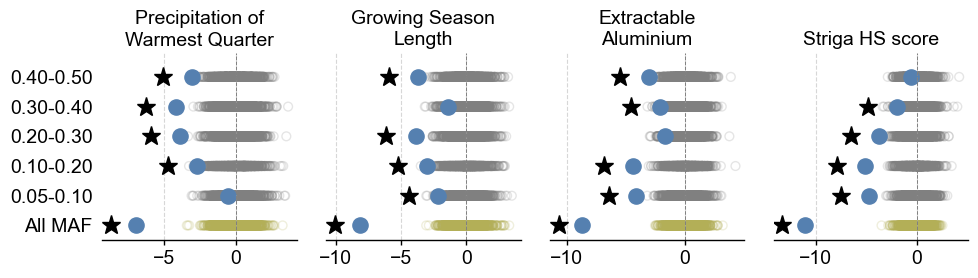

In [98]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.1.2 med_pi

In [99]:
contrast_id = "med_pi"

In [100]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: med_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: med_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/med_pi; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/med_pi/feature_coverage.json.gz')

Enrichment results for contrast: med_pi


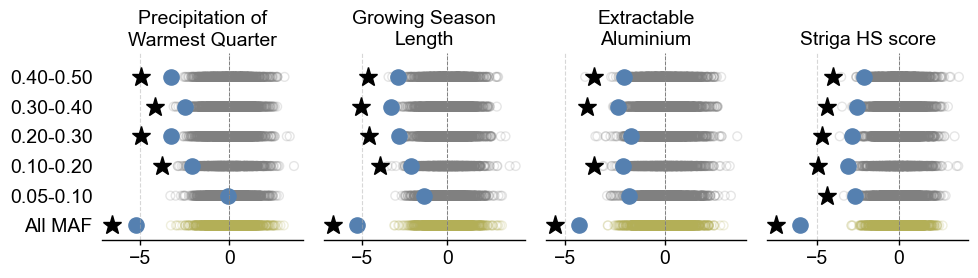

In [101]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.1.3 high_pi

In [102]:
contrast_id = "high_pi"

In [103]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: high_pi
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: high_pi & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/high_pi; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/high_pi/feature_coverage.json.gz')

Enrichment results for contrast: high_pi


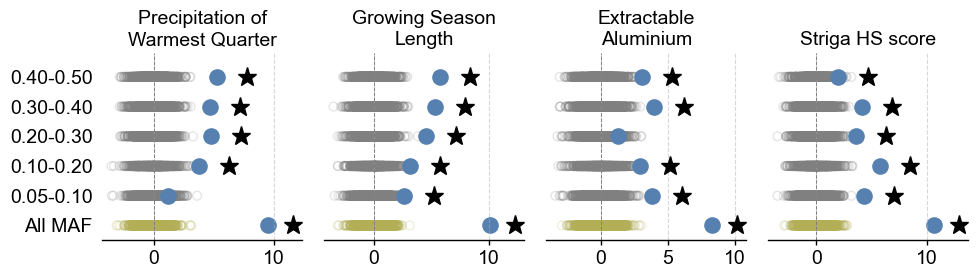

In [104]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

### 5.3 Phylogenetic conservation (PhyloP)

#### 5.3.1 non_CEs

In [105]:
contrast_id = "non_CEs"

In [106]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: non_CEs
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: non_CEs & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/non_CEs; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/non_CEs/feature_coverage.json.gz')

Enrichment results for contrast: non_CEs


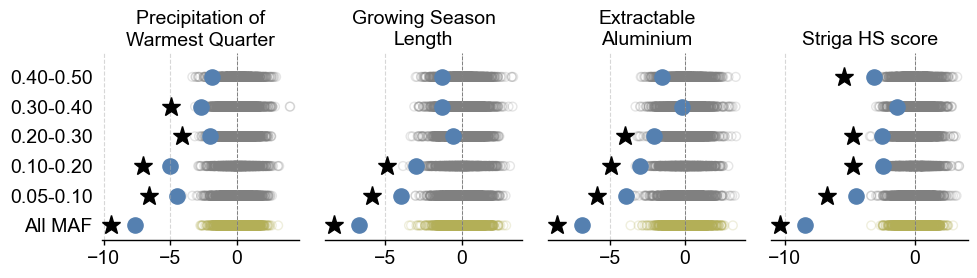

In [107]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.2 conserved_sites

In [108]:
contrast_id = "conserved_sites"

In [109]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: conserved_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: conserved_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/conserved_sites; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/conserved_sites/feature_coverage.json.gz')

Enrichment results for contrast: conserved_sites


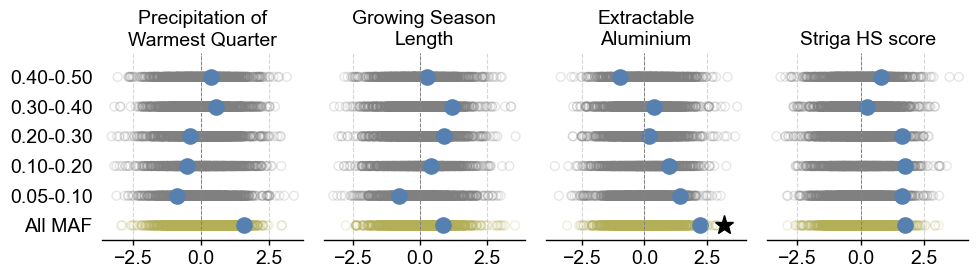

In [110]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.3 neutral_sites

In [111]:
contrast_id = "neutral_sites"

In [112]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: neutral_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: neutral_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/neutral_sites; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/neutral_sites/feature_coverage.json.gz')

Enrichment results for contrast: neutral_sites


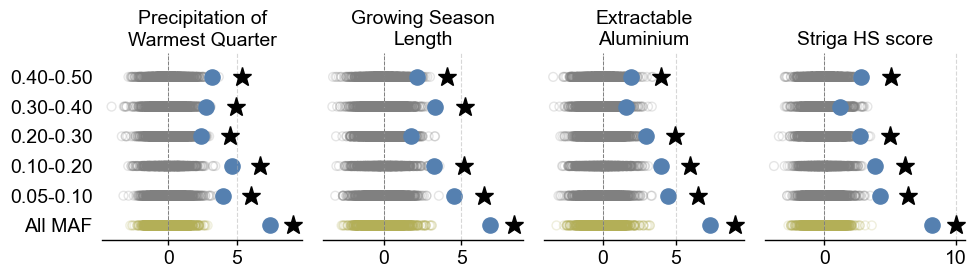

In [113]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

#### 5.3.4 accelerated_sites

In [114]:
contrast_id = "accelerated_sites"

In [115]:
from src.enrich import build_enrich_data_df
from src.feature_coverage import FEATURE_COVERAGE_JOB

permutations = 1000
top_percent = 0.05
ld_window_size = 15000
block_r2_threshold = 0.5
contrast = contrasts_settings[contrast_id]
print(f"Running enrichment for contrast: {contrast_id}")
print(f"Using dataset: {contrast['dataset']}")
print(f"Using permutations: {permutations}, top_percent: {top_percent}, pool_num: 30")
print(f"  Foreground set: {contrast['foreground']}")
print(f"  Background set: {contrast['background']}")
print(f"  MAF stratify: {contrast['maf_stratify']}")

context_df = datasets[contrast["dataset"]]
context_df = build_enrich_data_df(context_df, contrast, env_id_list, other_columns=[x for x in contrast['maf_stratify'] if x != 'all'])
output_dir = f"{enrich_dir}/{contrast_id}"

job = FEATURE_COVERAGE_JOB(
    input_data_df=context_df,
    input_vcf_file=vcf_files[contrast["dataset"]],
    output_dir=output_dir,
    env_id_list=env_id_list, maf_stratify=contrast['maf_stratify'],
    top_percent=top_percent, ld_window_size=ld_window_size,
    block_r2_threshold=block_r2_threshold, score_min_r2=0.2,
    permutations=permutations, pool_num=30,
    permutation_pool_num=30, silence=True,
)

job.run()

Running enrichment for contrast: accelerated_sites
Using dataset: genome
Using permutations: 1000, top_percent: 0.05, pool_num: 30
  Foreground set: accelerated_sites & genic_15kb
  Background set: genic_15kb
  MAF stratify: ['all', 'maf_0.05_0.1', 'maf_0.1_0.2', 'maf_0.2_0.3', 'maf_0.3_0.4', 'maf_0.4_0.5']
Feature coverage results already exist in /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/accelerated_sites; skipping run.


PosixPath('/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichmentv2/accelerated_sites/feature_coverage.json.gz')

Enrichment results for contrast: accelerated_sites


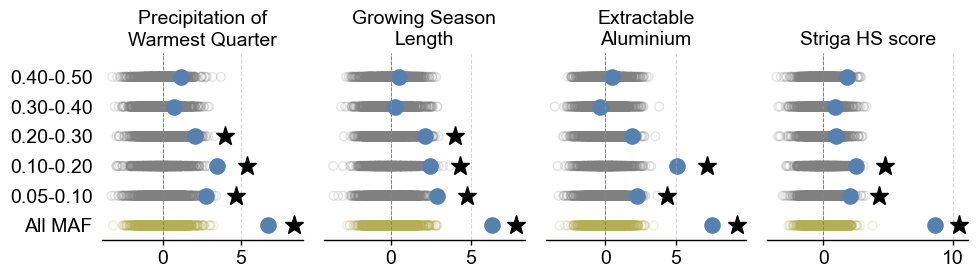

In [116]:
from src.enrich import plot_enrichment_with_stratify

stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.05_0.1', '0.05-0.10'],
    ['maf_0.1_0.2', '0.10-0.20'],
    ['maf_0.2_0.3', '0.20-0.30'],
    ['maf_0.3_0.4', '0.30-0.40'],
    ['maf_0.4_0.5', '0.40-0.50'],
]

results_json_file = f"{output_dir}/feature_coverage.json.gz"
with gzip.open(results_json_file, 'rt', encoding='utf-8') as f:
    results_json = json.load(f)

print(f"Enrichment results for contrast: {contrast_id}")
save_path = os.path.join(output_dir, f"feature_coverage.enrichment.pdf")
fig, axs = plot_enrichment_with_stratify(results_json, env_id_list, env_metadata_df, stratify_label_map)
fig.savefig(save_path, bbox_inches='tight')

simulate

In [117]:
simulation_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/simulation_results.csv")
simulation_results_df

,name,causal_foreground_fraction,enrichment_ratio,seed,pval,obs
0,s5000f1,0.01,NaN,4200,0.327672,0.941820
1,s5000f1,0.01,NaN,4300,0.225774,0.957132
2,s5000f1,0.01,NaN,4400,0.633367,1.024500
3,s5000f1,0.01,NaN,4500,0.003996,0.876303
4,s5000f1,0.01,NaN,4600,0.047952,1.094972
...,...,...,...,...,...,...
325,s5000f99,0.99,NaN,6700,0.001998,1.060000
326,s5000f99,0.99,NaN,6800,0.037962,1.093061
327,s5000f99,0.99,NaN,6900,0.261738,1.047686
328,s5000f99,0.99,NaN,7000,0.053946,1.105009


In [118]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_simulation_results(
    input_data,
    x_col="causal_foreground_fraction",
    obs_col="obs",
    pval_col="pval",
    figsize=(8, 5),
    log_x=False,
):
    if isinstance(input_data, (str, bytes)):
        df = pd.read_csv(input_data)
    else:
        df = input_data.copy()

    df = df[[x_col, obs_col, pval_col, "seed"]].dropna().copy()
    df[x_col] = pd.to_numeric(df[x_col])
    df[obs_col] = pd.to_numeric(df[obs_col])
    df[pval_col] = pd.to_numeric(df[pval_col])

    summary = (
        df.groupby(x_col)
        .agg(
            n=("seed", "nunique"),
            obs_mean=(obs_col, "mean"),
            obs_sd=(obs_col, "std"),
            obs_median=(obs_col, "median"),
            pval_median=(pval_col, "median"),
            pval_q25=(pval_col, lambda x: x.quantile(0.25)),
            pval_q75=(pval_col, lambda x: x.quantile(0.75)),
        )
        .reset_index()
        .sort_values(x_col)
    )

    x = summary[x_col].to_numpy()

    fig, ax1 = plt.subplots(figsize=figsize)
    ax2 = ax1.twinx()

    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    obs_color = colors[0]
    pval_color = colors[1]

    # Individual seed replicates
    ax1.scatter(
        df[x_col],
        df[obs_col],
        s=18,
        alpha=0.18,
        color=obs_color,
        linewidths=0,
    )

    ax2.scatter(
        df[x_col],
        df[pval_col],
        s=18,
        alpha=0.12,
        color=pval_color,
        linewidths=0,
    )

    # OBS: mean ± SD
    ax1.errorbar(
        x,
        summary["obs_mean"],
        yerr=summary["obs_sd"],
        marker="o",
        capsize=3,
        linewidth=1.8,
        color=obs_color,
        label="Observed enrichment",
    )

    # P-value: median + IQR
    pval_yerr = np.vstack([
        summary["pval_median"] - summary["pval_q25"],
        summary["pval_q75"] - summary["pval_median"],
    ])

    ax2.errorbar(
        x,
        summary["pval_median"],
        yerr=pval_yerr,
        marker="s",
        capsize=3,
        linewidth=1.8,
        color=pval_color,
        label="Permutation P-value",
    )

    # Reference lines
    ax1.axhline(
        1,
        linestyle="--",
        linewidth=1,
        alpha=0.6,
        color=obs_color,
    )

    ax2.axhline(
        0.05,
        linestyle="--",
        linewidth=1,
        alpha=0.6,
        color=pval_color,
    )

    ax1.set_xlabel("Causal foreground fraction")
    ax1.set_ylabel("Observed enrichment", color=obs_color)
    ax2.set_ylabel("Permutation P-value", color=pval_color)

    ax1.tick_params(axis="y", labelcolor=obs_color)
    ax2.tick_params(axis="y", labelcolor=pval_color)

    ax2.set_ylim(0, 1)

    if log_x:
        ax1.set_xscale("log")

    # Combined legend
    handles1, labels1 = ax1.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(
        handles1 + handles2,
        labels1 + labels2,
        frameon=False,
    )

    fig.tight_layout()

    return fig, ax1, ax2, summary

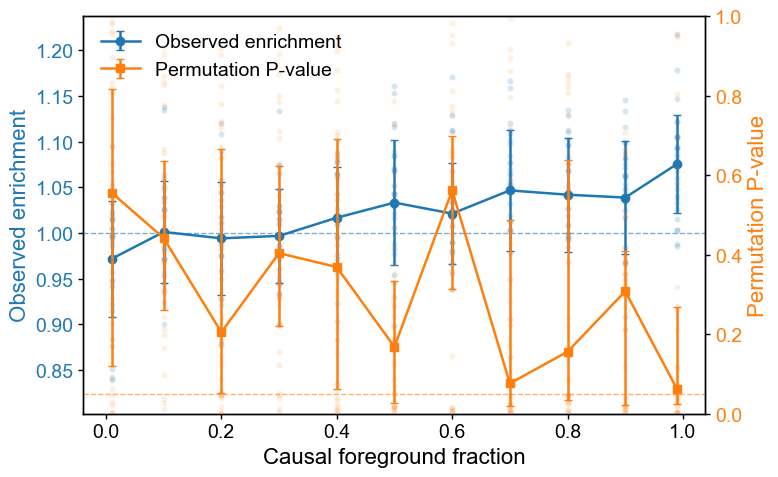

In [119]:
df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/simulation_results.csv")

fig, ax1, ax2, summary = plot_simulation_results(df)

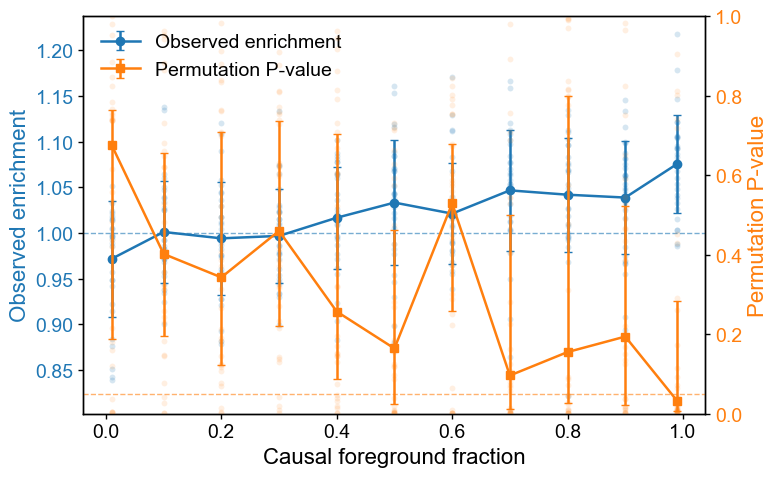

In [121]:
df = pd.read_csv(f'/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/simulate/simulation_results.csv')
df = df[df['causal_site_num'] == 5000]
fig, ax1, ax2, summary = plot_simulation_results(df)

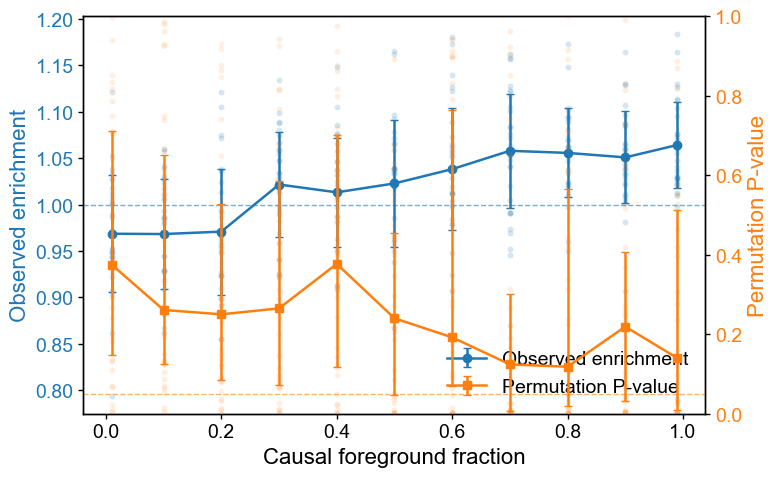

In [122]:
df = pd.read_csv(f'/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/simulate/simulation_results.csv')
df = df[df['causal_site_num'] == 500]
fig, ax1, ax2, summary = plot_simulation_results(df)

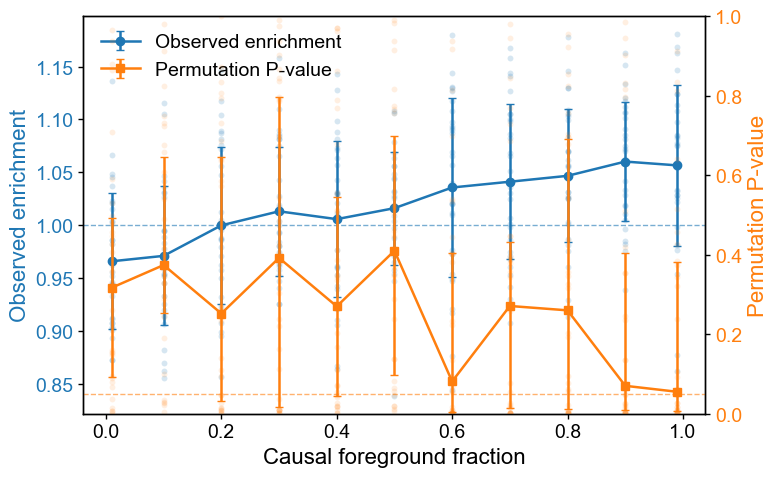

In [123]:
df = pd.read_csv(f'/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/simulate/simulation_results.csv')
df = df[df['causal_site_num'] == 50]
fig, ax1, ax2, summary = plot_simulation_results(df)